# Exploratory data analysis

### 1.Project Introduction and Research Questions

This project explores the relationship between music-listening habits and mental well-being using survey data. The analysis investigates how listening duration, genre preferences, age, and other listening habits are associated with self-reported anxiety, depression, insomnia, and OCD levels. Using Python and data analysis techniques, the goal is to identify patterns, explore relationships between variables, and extract meaningful insights from the data.

This analysis focuses on the following research questions. These questions explore how listening habits, musical preferences, and demographic factors are associated with self-reported mental health indicators:
#### RQ1. Music and mood

How is listening to music associated with people's moods and emotional well-being?


#### RQ2. Music genres and psychological effects

Are different music genres associated with different emotional experiences or psychological outcomes?


#### RQ3. Age differences

Does the relationship between music listening and psychological well-being differ across age groups?


#### RQ4. Listening duration

Is the amount of time spent listening to music associated with mood, stress, or psychological well-being?


### 2.Data Loading and Initial Inspection

In [5]:
#importing  libraries
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Check versions
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", stats.__version__ if hasattr(stats, "__version__") else "Installed")
print("Libraries imported successfully!")


Pandas: 2.2.2
NumPy: 1.26.4
SciPy: Installed
Libraries imported successfully!


In [6]:
#importing the dataset:
df=pd.read_csv(r"C:\Users\HP\Desktop\Music_effect_data_analysis_project\Dataset.csv")
df.shape

(736, 33)

In [7]:
df.head()

,Timestamp,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,BPM,Frequency [Classical],Frequency [Country],Frequency [EDM],Frequency [Folk],Frequency [Gospel],Frequency [Hip hop],Frequency [Jazz],Frequency [K pop],Frequency [Latin],Frequency [Lofi],Frequency [Metal],Frequency [Pop],Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects,Permissions
0,8/27/2022 19:29:02,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,156.0,Rarely,Never,Rarely,Never,Never,Sometimes,Never,Very frequently,Very frequently,Rarely,Never,Very frequently,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN,I understand.
1,8/27/2022 19:57:31,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,119.0,Sometimes,Never,Never,Rarely,Sometimes,Rarely,Very frequently,Rarely,Sometimes,Rarely,Never,Sometimes,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN,I understand.
2,8/27/2022 21:28:18,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,132.0,Never,Never,Very frequently,Never,Never,Rarely,Rarely,Very frequently,Never,Sometimes,Sometimes,Rarely,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect,I understand.
3,8/27/2022 21:40:40,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,Yes,Yes,84.0,Sometimes,Never,Never,Rarely,Sometimes,Never,Very frequently,Sometimes,Very frequently,Sometimes,Never,Sometimes,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve,I understand.
4,8/27/2022 21:54:47,18.0,Spotify,4.0,Yes,No,No,R&B,Yes,No,107.0,Never,Never,Rarely,Never,Rarely,Very frequently,Never,Very frequently,Sometimes,Sometimes,Never,Sometimes,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve,I understand.


In [8]:
df.info

<bound method DataFrame.info of                Timestamp   Age Primary streaming service  Hours per day  \
0     8/27/2022 19:29:02  18.0                   Spotify            3.0   
1     8/27/2022 19:57:31  63.0                   Pandora            1.5   
2     8/27/2022 21:28:18  18.0                   Spotify            4.0   
3     8/27/2022 21:40:40  61.0             YouTube Music            2.5   
4     8/27/2022 21:54:47  18.0                   Spotify            4.0   
..                   ...   ...                       ...            ...   
731  10/30/2022 14:37:28  17.0                   Spotify            2.0   
732   11/1/2022 22:26:42  18.0                   Spotify            1.0   
733   11/3/2022 23:24:38  19.0   Other streaming service            6.0   
734   11/4/2022 17:31:47  19.0                   Spotify            5.0   
735    11/9/2022 1:55:20  29.0             YouTube Music            2.0   

    While working Instrumentalist Composer         Fav genre Explor

In [9]:
df.dtypes

Timestamp                        object
Age                             float64
Primary streaming service        object
Hours per day                   float64
While working                    object
Instrumentalist                  object
Composer                         object
Fav genre                        object
Exploratory                      object
Foreign languages                object
BPM                             float64
Frequency [Classical]            object
Frequency [Country]              object
Frequency [EDM]                  object
Frequency [Folk]                 object
Frequency [Gospel]               object
Frequency [Hip hop]              object
Frequency [Jazz]                 object
Frequency [K pop]                object
Frequency [Latin]                object
Frequency [Lofi]                 object
Frequency [Metal]                object
Frequency [Pop]                  object
Frequency [R&B]                  object
Frequency [Rap]                  object


### 3. Data Quality Assessment

In [16]:
# Missing values per column
df.isnull().sum()

Timestamp                         0
Age                               1
Primary streaming service         1
Hours per day                     0
While working                     3
Instrumentalist                   4
Composer                          1
Fav genre                         0
Exploratory                       0
Foreign languages                 4
BPM                             107
Frequency [Classical]             0
Frequency [Country]               0
Frequency [EDM]                   0
Frequency [Folk]                  0
Frequency [Gospel]                0
Frequency [Hip hop]               0
Frequency [Jazz]                  0
Frequency [K pop]                 0
Frequency [Latin]                 0
Frequency [Lofi]                  0
Frequency [Metal]                 0
Frequency [Pop]                   0
Frequency [R&B]                   0
Frequency [Rap]                   0
Frequency [Rock]                  0
Frequency [Video game music]      0
Anxiety                     

In [18]:
# Percentage of missing values per column
df.isnull().mean().mul(100).round(2)

Timestamp                        0.00
Age                              0.14
Primary streaming service        0.14
Hours per day                    0.00
While working                    0.41
Instrumentalist                  0.54
Composer                         0.14
Fav genre                        0.00
Exploratory                      0.00
Foreign languages                0.54
BPM                             14.54
Frequency [Classical]            0.00
Frequency [Country]              0.00
Frequency [EDM]                  0.00
Frequency [Folk]                 0.00
Frequency [Gospel]               0.00
Frequency [Hip hop]              0.00
Frequency [Jazz]                 0.00
Frequency [K pop]                0.00
Frequency [Latin]                0.00
Frequency [Lofi]                 0.00
Frequency [Metal]                0.00
Frequency [Pop]                  0.00
Frequency [R&B]                  0.00
Frequency [Rap]                  0.00
Frequency [Rock]                 0.00
Frequency [V

In [20]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum()
})
display(missing.sort_values("missing_count", ascending=False))

,missing_count
BPM,107
Music effects,8
Instrumentalist,4
Foreign languages,4
While working,3
Primary streaming service,1
Composer,1
Age,1
Frequency [Video game music],0
Frequency [Pop],0


In [22]:
# Total number of missing cells
df.isnull().sum().sum()

129

In [24]:
#checking duplicate rows
df.duplicated().sum()

0

In [26]:
#checking the number of unique values per column
df.nunique()

Timestamp                       735
Age                              61
Primary streaming service         6
Hours per day                    27
While working                     2
Instrumentalist                   2
Composer                          2
Fav genre                        16
Exploratory                       2
Foreign languages                 2
BPM                             135
Frequency [Classical]             4
Frequency [Country]               4
Frequency [EDM]                   4
Frequency [Folk]                  4
Frequency [Gospel]                4
Frequency [Hip hop]               4
Frequency [Jazz]                  4
Frequency [K pop]                 4
Frequency [Latin]                 4
Frequency [Lofi]                  4
Frequency [Metal]                 4
Frequency [Pop]                   4
Frequency [R&B]                   4
Frequency [Rap]                   4
Frequency [Rock]                  4
Frequency [Video game music]      4
Anxiety                     

In [28]:
# Unique values in categorical columns
for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))


Timestamp:
Timestamp
8/28/2022 16:15:08    2
8/27/2022 19:29:02    1
9/1/2022 21:07:33     1
9/1/2022 19:09:32     1
9/1/2022 19:36:54     1
9/1/2022 19:39:07     1
9/1/2022 19:39:49     1
9/1/2022 19:44:33     1
9/1/2022 20:02:19     1
9/1/2022 20:36:10     1
9/1/2022 21:05:57     1
9/1/2022 21:14:09     1
9/1/2022 18:38:46     1
9/1/2022 21:24:34     1
9/1/2022 21:44:49     1
Name: count, dtype: int64

Primary streaming service:
Primary streaming service
Spotify                              458
YouTube Music                         94
I do not use a streaming service.     71
Apple Music                           51
Other streaming service               50
Pandora                               11
NaN                                    1
Name: count, dtype: int64

While working:
While working
Yes    579
No     154
NaN      3
Name: count, dtype: int64

Instrumentalist:
Instrumentalist
No     497
Yes    235
NaN      4
Name: count, dtype: int64

Composer:
Composer
No     609
Yes    126
N

In [30]:
# Examine summary statistics
df.describe()

,Age,Hours per day,BPM,Anxiety,Depression,Insomnia,OCD
count,735.000000,736.000000,6.290000e+02,736.000000,736.000000,736.000000,736.000000
mean,25.206803,3.572758,1.589948e+06,5.837636,4.796196,3.738451,2.637228
std,12.054970,3.028199,3.987261e+07,2.793054,3.028870,3.088689,2.842017
min,10.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,18.000000,2.000000,1.000000e+02,4.000000,2.000000,1.000000,0.000000
50%,21.000000,3.000000,1.200000e+02,6.000000,5.000000,3.000000,2.000000
75%,28.000000,5.000000,1.440000e+02,8.000000,7.000000,6.000000,5.000000
max,89.000000,24.000000,1.000000e+09,10.000000,10.000000,10.000000,10.000000


In [32]:
# Categorical and other columns
df.describe(include="all")

,Timestamp,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,BPM,Frequency [Classical],Frequency [Country],Frequency [EDM],Frequency [Folk],Frequency [Gospel],Frequency [Hip hop],Frequency [Jazz],Frequency [K pop],Frequency [Latin],Frequency [Lofi],Frequency [Metal],Frequency [Pop],Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects,Permissions
count,736,735.000000,735,736.000000,733,732,735,736,736,732,6.290000e+02,736,736,736,736,736,736,736,736,736,736,736,736,736,736,736,736,736.000000,736.000000,736.000000,736.000000,728,736
unique,735,NaN,6,NaN,2,2,2,16,2,2,NaN,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,NaN,NaN,NaN,NaN,3,1
top,8/28/2022 16:15:08,NaN,Spotify,NaN,Yes,No,No,Rock,Yes,Yes,NaN,Rarely,Never,Never,Never,Never,Sometimes,Never,Never,Never,Never,Never,Very frequently,Never,Rarely,Very frequently,Never,NaN,NaN,NaN,NaN,Improve,I understand.
freq,2,NaN,458,NaN,579,497,609,188,525,404,NaN,259,343,307,292,535,218,261,416,443,280,264,277,225,215,330,236,NaN,NaN,NaN,NaN,542,736
mean,NaN,25.206803,NaN,3.572758,NaN,NaN,NaN,NaN,NaN,NaN,1.589948e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.837636,4.796196,3.738451,2.637228,NaN,NaN
std,NaN,12.054970,NaN,3.028199,NaN,NaN,NaN,NaN,NaN,NaN,3.987261e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.793054,3.028870,3.088689,2.842017,NaN,NaN
min,NaN,10.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,18.000000,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,2.000000,1.000000,0.000000,NaN,NaN
50%,NaN,21.000000,NaN,3.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.200000e+02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,5.000000,3.000000,2.000000,NaN,NaN
75%,NaN,28.000000,NaN,5.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.440000e+02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,7.000000,6.000000,5.000000,NaN,NaN


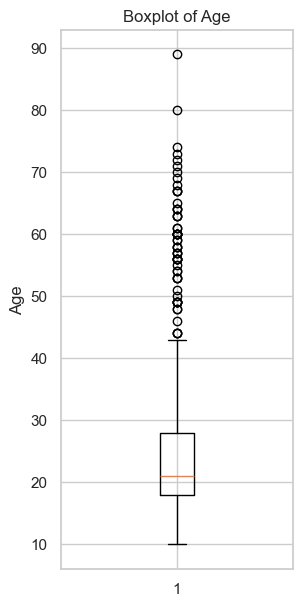

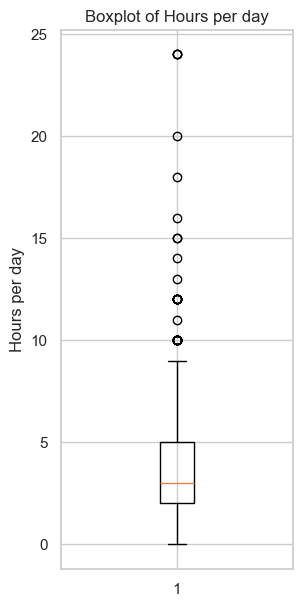

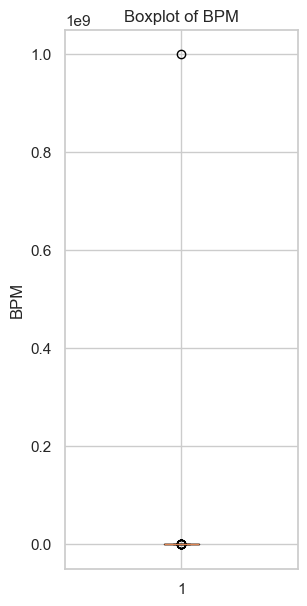

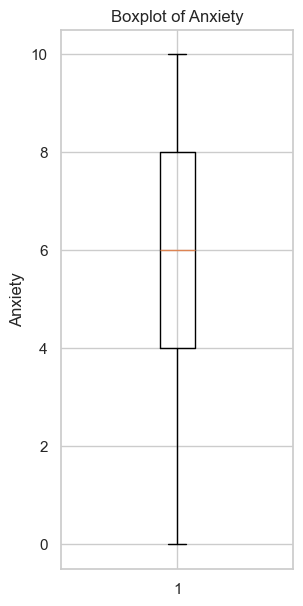

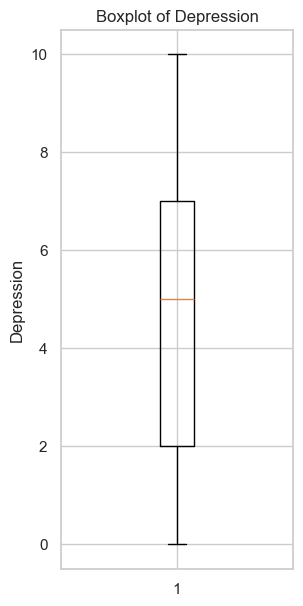

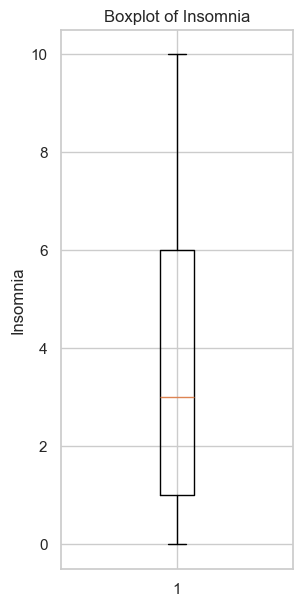

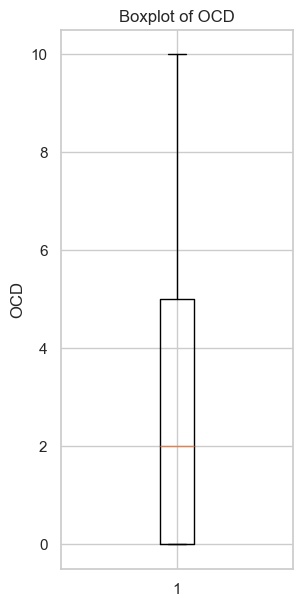

In [34]:
#Investigating outliers and invalid values
#select numerical columns
numeric_df=df.select_dtypes(include="number")

#Boxplot for numerical variables
for col in numeric_df.columns:
    plt.figure(figsize=(3,7))
    plt.boxplot(df[col].dropna())
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
    plt.show()


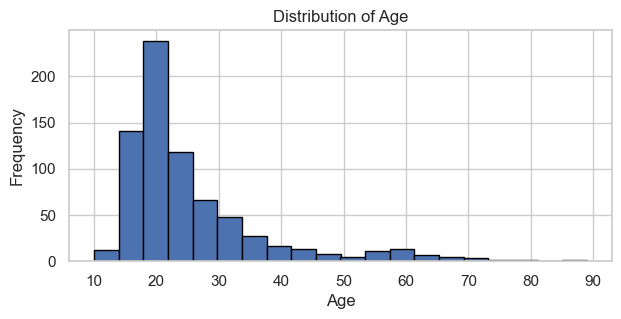

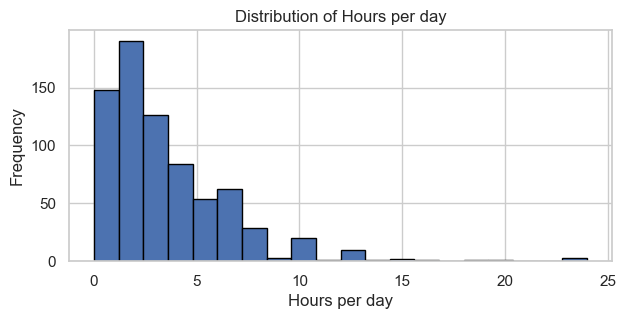

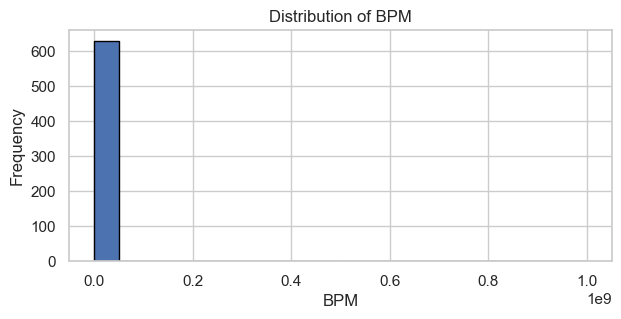

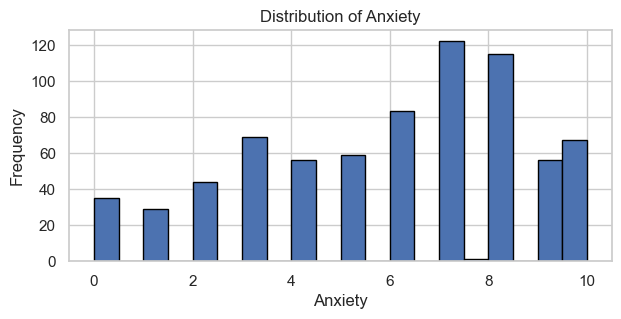

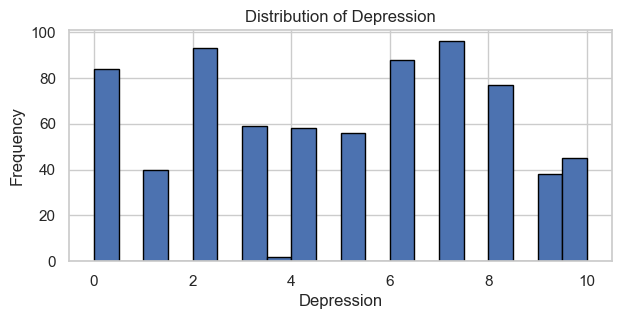

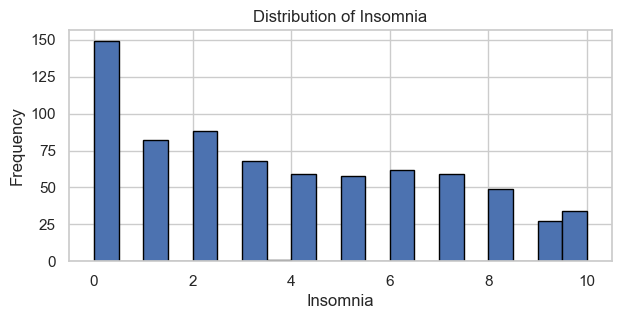

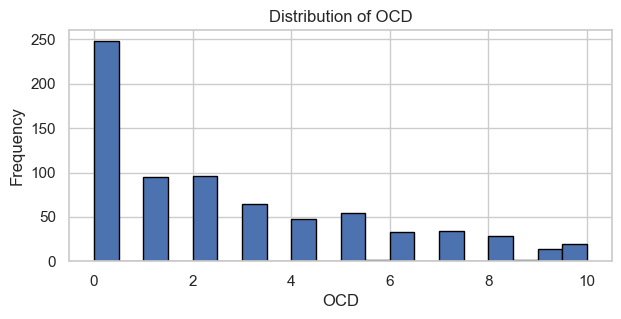

In [35]:
#Exploring distributions
# Histograms for numerical columns
for col in numeric_df.columns:
    plt.figure(figsize=(7, 3))
    plt.hist(df[col].dropna(), bins=20, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [36]:
# Correlations between numerical columns
correlation = numeric_df.corr()
print(correlation)

                    Age  Hours per day       BPM   Anxiety  Depression  \
Age            1.000000      -0.044638 -0.029928 -0.176662   -0.121563   
Hours per day -0.044638       1.000000  0.042554  0.049319    0.110527   
BPM           -0.029928       0.042554  1.000000 -0.027050    0.041371   
Anxiety       -0.176662       0.049319 -0.027050  1.000000    0.519969   
Depression    -0.121563       0.110527  0.041371  0.519969    1.000000   
Insomnia       0.006909       0.141821  0.053591  0.292669    0.378996   
OCD           -0.130114       0.118729  0.018927  0.348350    0.196988   

               Insomnia       OCD  
Age            0.006909 -0.130114  
Hours per day  0.141821  0.118729  
BPM            0.053591  0.018927  
Anxiety        0.292669  0.348350  
Depression     0.378996  0.196988  
Insomnia       1.000000  0.226354  
OCD            0.226354  1.000000  


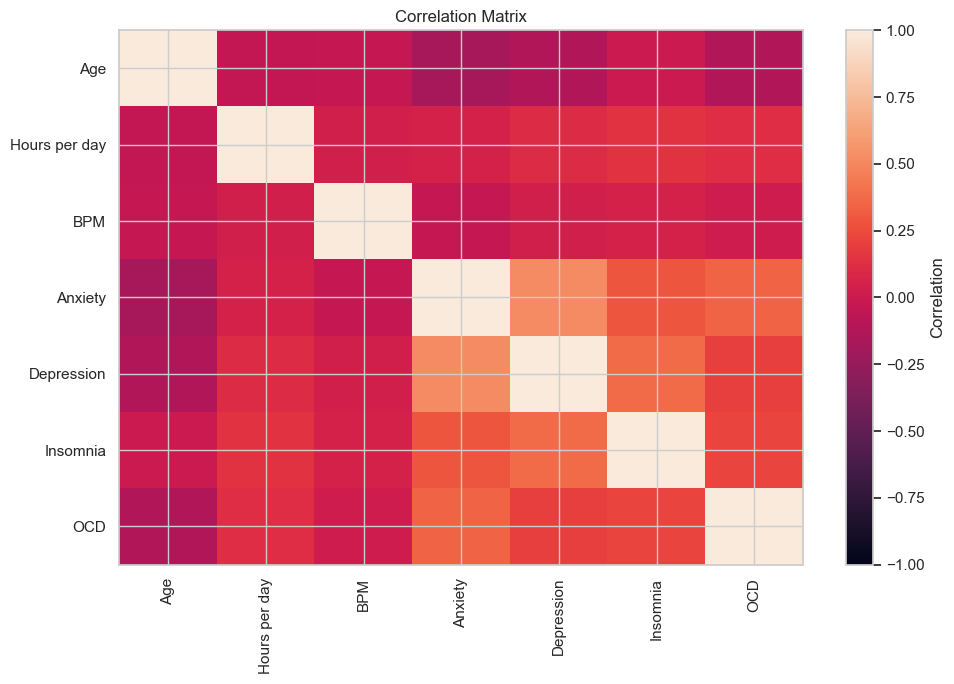

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
plt.imshow(correlation, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)),
           correlation.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### 4. Data Cleaning and Preparation

In [40]:
#creatinf a raw data backup
df_raw = df.copy()

In [41]:
#fixing column names and formats
# Standardizing column names
df.columns=(
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)
# Removing leading/trailing whitespace from text columns
text_cols=df.select_dtypes(include=["object","string"]).columns

for col in text_cols:
    df[col]=df[col].str.strip()

#dropping unneeded columns:
df = df.drop(columns=["timestamp", "permissions", "bpm"])
print(df.columns.tolist())

['age', 'primary_streaming_service', 'hours_per_day', 'while_working', 'instrumentalist', 'composer', 'fav_genre', 'exploratory', 'foreign_languages', 'frequency_[classical]', 'frequency_[country]', 'frequency_[edm]', 'frequency_[folk]', 'frequency_[gospel]', 'frequency_[hip_hop]', 'frequency_[jazz]', 'frequency_[k_pop]', 'frequency_[latin]', 'frequency_[lofi]', 'frequency_[metal]', 'frequency_[pop]', 'frequency_[r&b]', 'frequency_[rap]', 'frequency_[rock]', 'frequency_[video_game_music]', 'anxiety', 'depression', 'insomnia', 'ocd', 'music_effects']


In [44]:
#validating numeric columns:
for c in ["age", "hours_per_day", "anxiety", "depression", "insomnia", "ocd"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df.loc[~df["age"].between(10, 100), "age"] = np.nan
df.loc[~df["hours_per_day"].between(0, 24), "hours_per_day"] = np.nan
for c in ["anxiety", "depression", "insomnia", "ocd"]:
    df.loc[~df[c].between(0, 10), c] = np.nan

# looking for extreme values
print(df[["age", "hours_per_day"]].describe())  

              age  hours_per_day
count  735.000000     736.000000
mean    25.206803       3.572758
std     12.054970       3.028199
min     10.000000       0.000000
25%     18.000000       2.000000
50%     21.000000       3.000000
75%     28.000000       5.000000
max     89.000000      24.000000


In [49]:
#handeling missing values
# Dropping the null rows of music_effects because Labeling those rows “Unknown” would add a meaningless category the main outcome
df = df.dropna(subset=["music_effects"])

# Core numeric variables: replacing them with median
for c in ["age", "hours_per_day", "anxiety", "depression", "insomnia", "ocd"]:
    df[c] = df[c].fillna(df[c].median())

# Other categorical columns
cat_cols = ["primary_streaming_service", "while_working", "instrumentalist",
            "composer", "foreign_languages", "exploratory", "fav_genre"]
df[cat_cols] = df[cat_cols].fillna("Unknown")


In [51]:
#Encoding the genre frequency columns
freq_map = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Very frequently": 3}
freq_cols = [c for c in df.columns if c.startswith("frequency_")]
df[freq_cols] = df[freq_cols].apply(lambda s: s.map(freq_map))

In [53]:
df[freq_cols].isna().sum()

frequency_[classical]           0
frequency_[country]             0
frequency_[edm]                 0
frequency_[folk]                0
frequency_[gospel]              0
frequency_[hip_hop]             0
frequency_[jazz]                0
frequency_[k_pop]               0
frequency_[latin]               0
frequency_[lofi]                0
frequency_[metal]               0
frequency_[pop]                 0
frequency_[r&b]                 0
frequency_[rap]                 0
frequency_[rock]                0
frequency_[video_game_music]    0
dtype: int64

In [55]:
#Creating new variables for the research questions
# RQ3: age groups
df["age_group"] = pd.cut(df["age"], bins=[0, 17, 24, 34, 49, 100],
                         labels=["<18", "18-24", "25-34", "35-49", "50+"])

# RQ1/RQ4: overall well-being score (higher = worse)
df["mental_health_score"] = df[["anxiety", "depression", "insomnia", "ocd"]].mean(axis=1)

# RQ4: listening duration groups
df["listening_group"] = pd.cut(df["hours_per_day"], bins=[-0.1, 1, 3, 6, 24],
                               labels=["<1h", "1-3h", "3-6h", "6h+"])

In [57]:
df["age_group"].value_counts()

age_group
18-24    329
<18      153
25-34    144
35-49     56
50+       46
Name: count, dtype: int64

### 5.Data Quality Check

In [60]:
print(df.isna().sum()[lambda s: s > 0])
print(df.shape)
print(df.dtypes)

Series([], dtype: int64)
(728, 33)
age                              float64
primary_streaming_service         object
hours_per_day                    float64
while_working                     object
instrumentalist                   object
composer                          object
fav_genre                         object
exploratory                       object
foreign_languages                 object
frequency_[classical]              int64
frequency_[country]                int64
frequency_[edm]                    int64
frequency_[folk]                   int64
frequency_[gospel]                 int64
frequency_[hip_hop]                int64
frequency_[jazz]                   int64
frequency_[k_pop]                  int64
frequency_[latin]                  int64
frequency_[lofi]                   int64
frequency_[metal]                  int64
frequency_[pop]                    int64
frequency_[r&b]                    int64
frequency_[rap]                    int64
frequency_[rock]      

In [62]:
df.isna().sum()

age                             0
primary_streaming_service       0
hours_per_day                   0
while_working                   0
instrumentalist                 0
composer                        0
fav_genre                       0
exploratory                     0
foreign_languages               0
frequency_[classical]           0
frequency_[country]             0
frequency_[edm]                 0
frequency_[folk]                0
frequency_[gospel]              0
frequency_[hip_hop]             0
frequency_[jazz]                0
frequency_[k_pop]               0
frequency_[latin]               0
frequency_[lofi]                0
frequency_[metal]               0
frequency_[pop]                 0
frequency_[r&b]                 0
frequency_[rap]                 0
frequency_[rock]                0
frequency_[video_game_music]    0
anxiety                         0
depression                      0
insomnia                        0
ocd                             0
music_effects 

In [64]:
print(df["listening_group"].value_counts())

listening_group
1-3h    310
3-6h    185
<1h     146
6h+      87
Name: count, dtype: int64


In [66]:
print(df["music_effects"].value_counts())

music_effects
Improve      542
No effect    169
Worsen        17
Name: count, dtype: int64


### 6.EDA on cleaned dataset

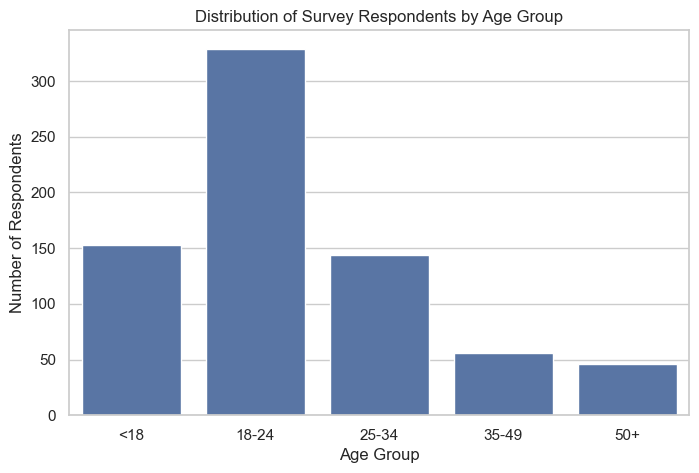

In [69]:
#Age distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="age_group")
plt.title("Distribution of Survey Respondents by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Respondents")
plt.show()

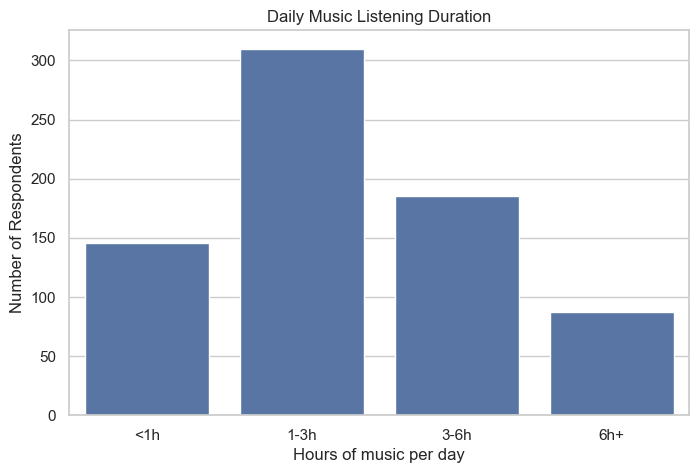

In [71]:
#listening hours
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="listening_group")
plt.title("Daily Music Listening Duration")
plt.xlabel("Hours of music per day")
plt.ylabel("Number of Respondents")
plt.show()

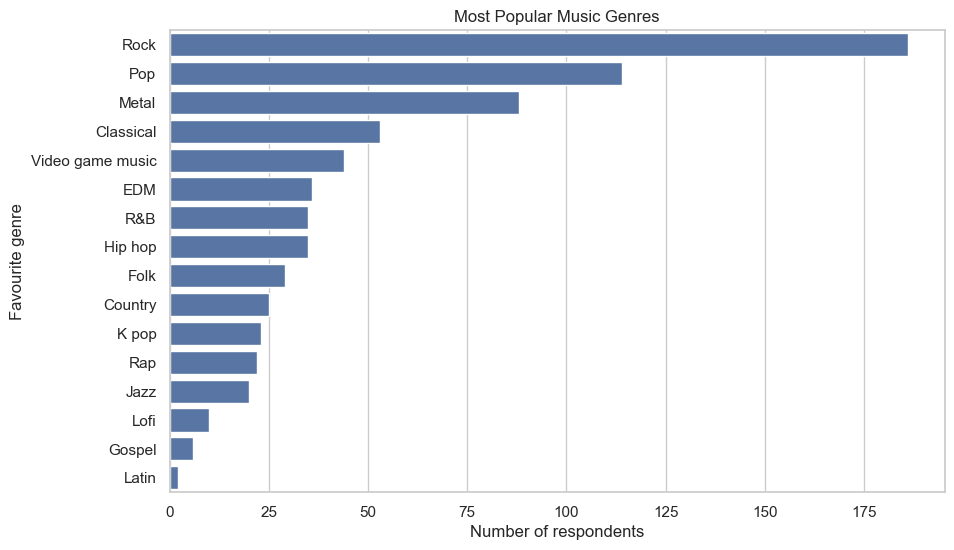

In [73]:
#Most popular genres
genre_counts = df["fav_genre"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("Most Popular Music Genres")
plt.xlabel("Number of respondents")
plt.ylabel("Favourite genre")
plt.show()

In [75]:
cols = ["anxiety", "depression", "insomnia", "ocd"]

# Distribution of each score (0-10)
for c in cols:
    print(c)
    print(df[c].value_counts().sort_index(), "\n")

anxiety
anxiety
0.0      34
1.0      29
2.0      44
3.0      66
4.0      55
5.0      59
6.0      83
7.0     121
7.5       1
8.0     114
9.0      56
10.0     66
Name: count, dtype: int64 

depression
depression
0.0     83
1.0     40
2.0     90
3.0     58
3.5      2
4.0     58
5.0     55
6.0     88
7.0     96
8.0     77
9.0     37
10.0    44
Name: count, dtype: int64 

insomnia
insomnia
0.0     148
1.0      80
2.0      85
3.0      68
3.5       1
4.0      59
5.0      57
6.0      61
7.0      59
8.0      49
9.0      27
10.0     34
Name: count, dtype: int64 

ocd
ocd
0.0     244
1.0      94
2.0      95
3.0      64
4.0      48
5.0      53
5.5       1
6.0      33
7.0      33
8.0      28
8.5       1
9.0      14
10.0     20
Name: count, dtype: int64 



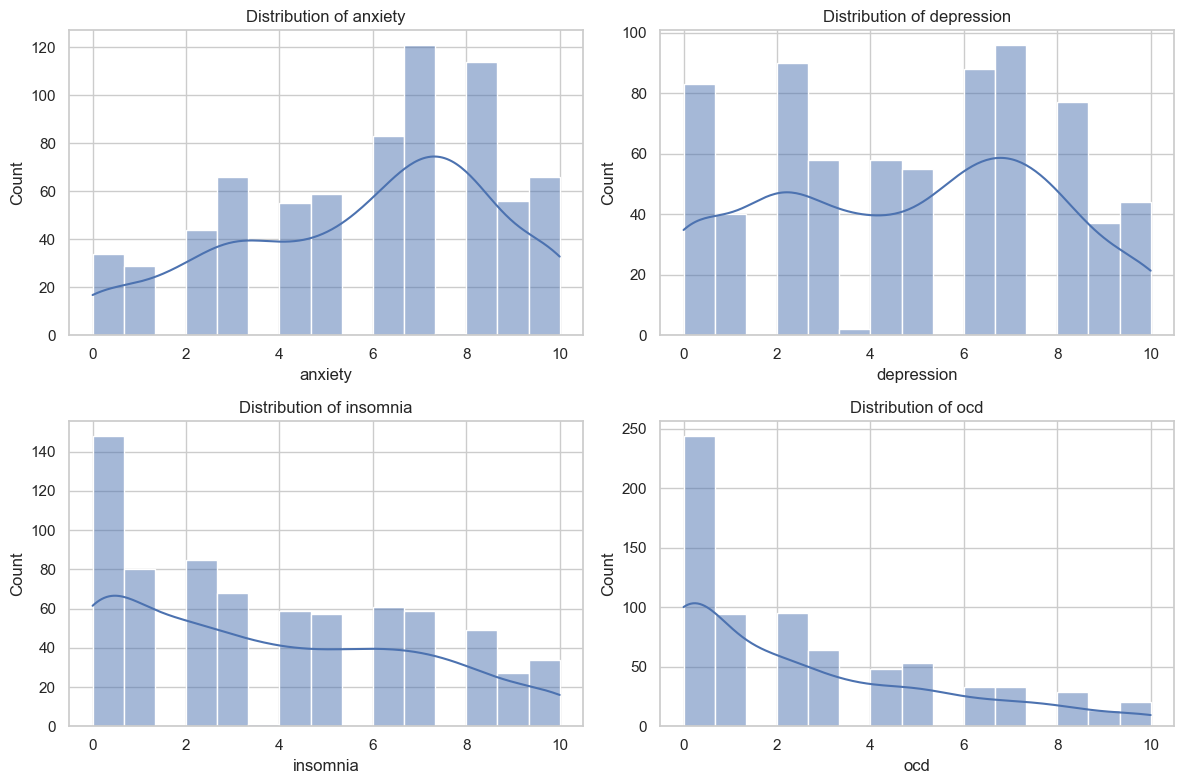

In [77]:
#Psychological score distributions
mental_cols = ["anxiety", "depression", "insomnia", "ocd"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(mental_cols, axes.flatten()):
    sns.histplot(data=df, x=col, bins=15, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

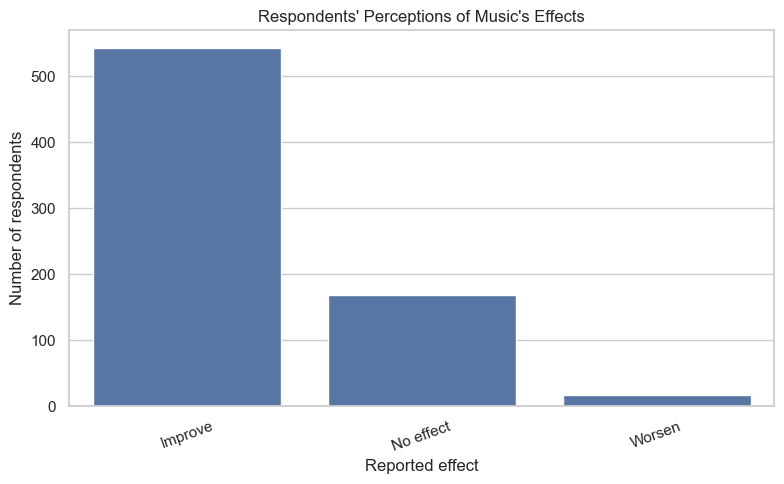

In [78]:
#RQ1. How is music associated with psychological well-being
#Reported effects of music
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="music_effects",
    order=df["music_effects"].value_counts().index
)

plt.title("Respondents' Perceptions of Music's Effects")
plt.xlabel("Reported effect")
plt.ylabel("Number of respondents")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

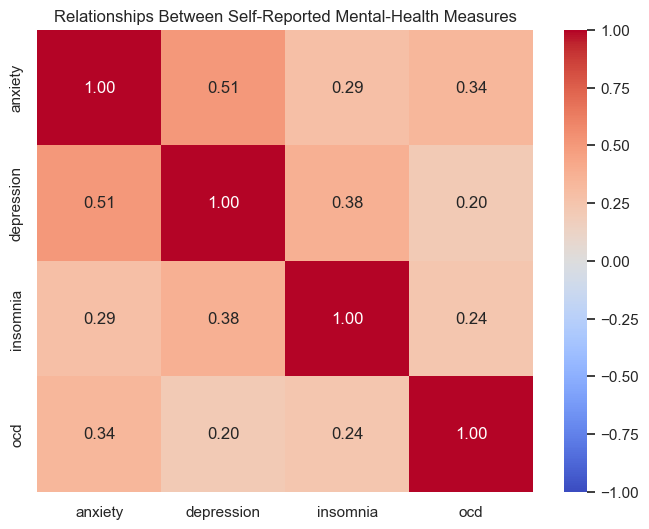

In [79]:
#Relationships between psychological measures
mental_cols = ["anxiety", "depression", "insomnia", "ocd"]

corr = df[mental_cols].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".2f")
plt.title("Relationships Between Self-Reported Mental-Health Measures")
plt.show()

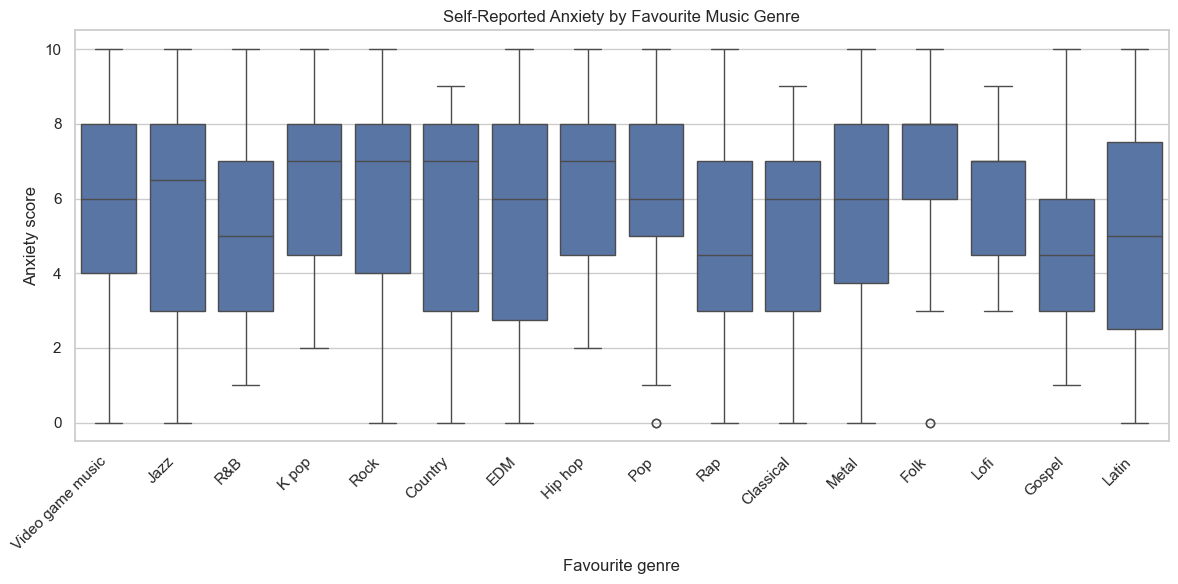

In [81]:
#RQ2. Do different music genres relate to different psychological outcomes?
#comparing psychological scores across respondents' favourite genres
#A-Anxiety by favourite genre
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="fav_genre", y="anxiety")

plt.title("Self-Reported Anxiety by Favourite Music Genre")
plt.xlabel("Favourite genre")
plt.ylabel("Anxiety score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

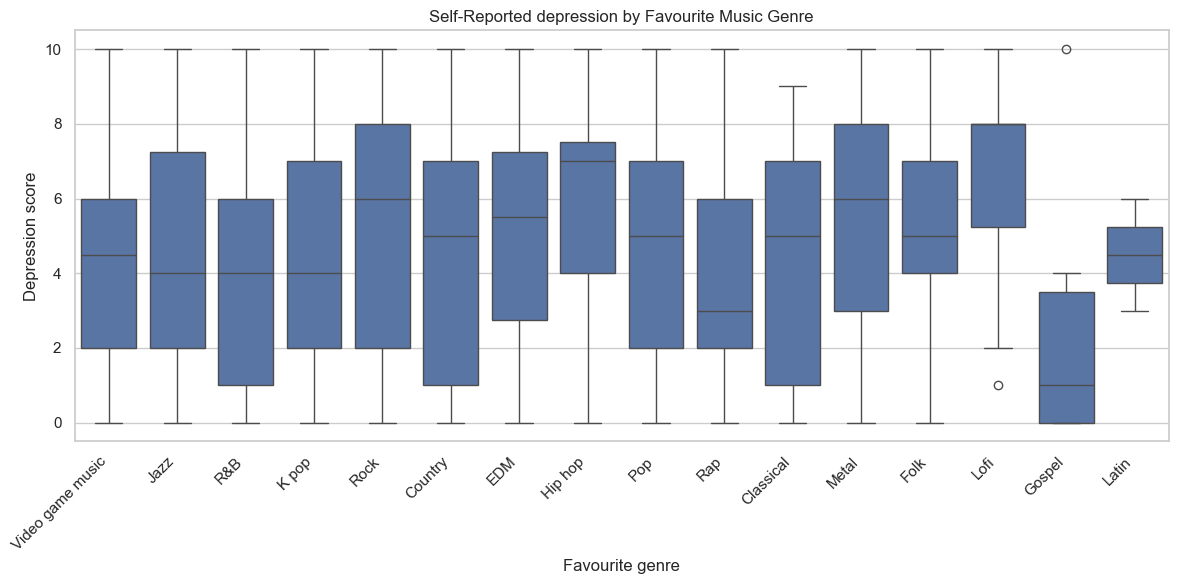

In [83]:
#B-Depression by favourite genre
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="fav_genre", y="depression")

plt.title("Self-Reported depression by Favourite Music Genre")
plt.xlabel("Favourite genre")
plt.ylabel("Depression score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

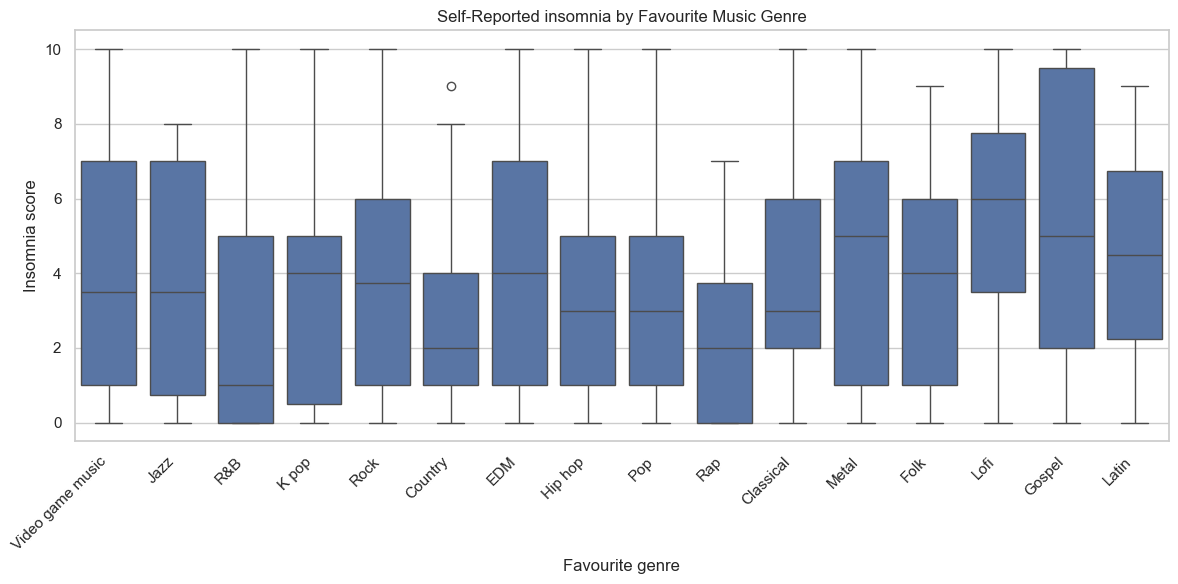

In [85]:
#C-Insomnia by favourite genre
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="fav_genre", y="insomnia")

plt.title("Self-Reported insomnia by Favourite Music Genre")
plt.xlabel("Favourite genre")
plt.ylabel("Insomnia score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

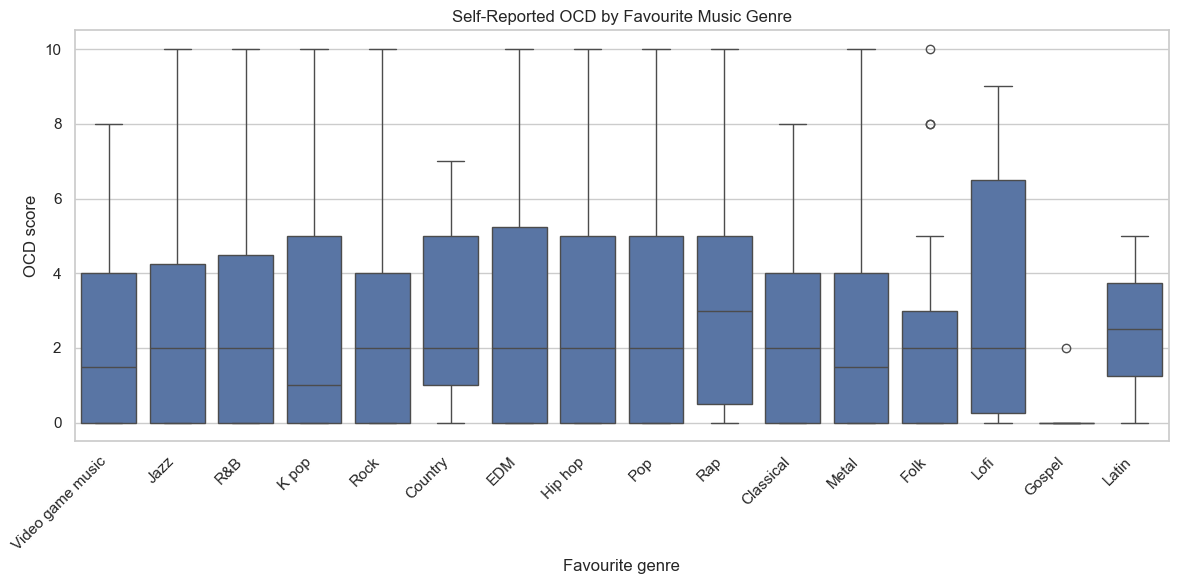

In [87]:
#D-OCD by favourite genre
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="fav_genre", y="ocd")

plt.title("Self-Reported OCD by Favourite Music Genre")
plt.xlabel("Favourite genre")
plt.ylabel("OCD score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [89]:
#Test whether the differences are statistically significant
#Comparing anxiety scores across favourite genres using the Kruskal–Wallis test
from scipy.stats import kruskal

genre_groups = [
    group["anxiety"].dropna()
    for _, group in df.groupby("fav_genre")
]

genre_groups = [g for g in genre_groups if len(g) >= 2]

statistic, p_value = kruskal(*genre_groups)

print("Kruskal-Wallis statistic:", statistic)
print("P-value:", p_value)
#This test does not tell you which genres differ. If the result is significant, you can follow up with pairwise comparisons and correct for multiple testing. Also check group sizes and ties in the scores.

#Important: This compares mental-health scores across groups defined by favourite genre. It does not prove that listening to a particular genre produces a particular psychological effect.

Kruskal-Wallis statistic: 19.07265238776755
P-value: 0.21046049515395152


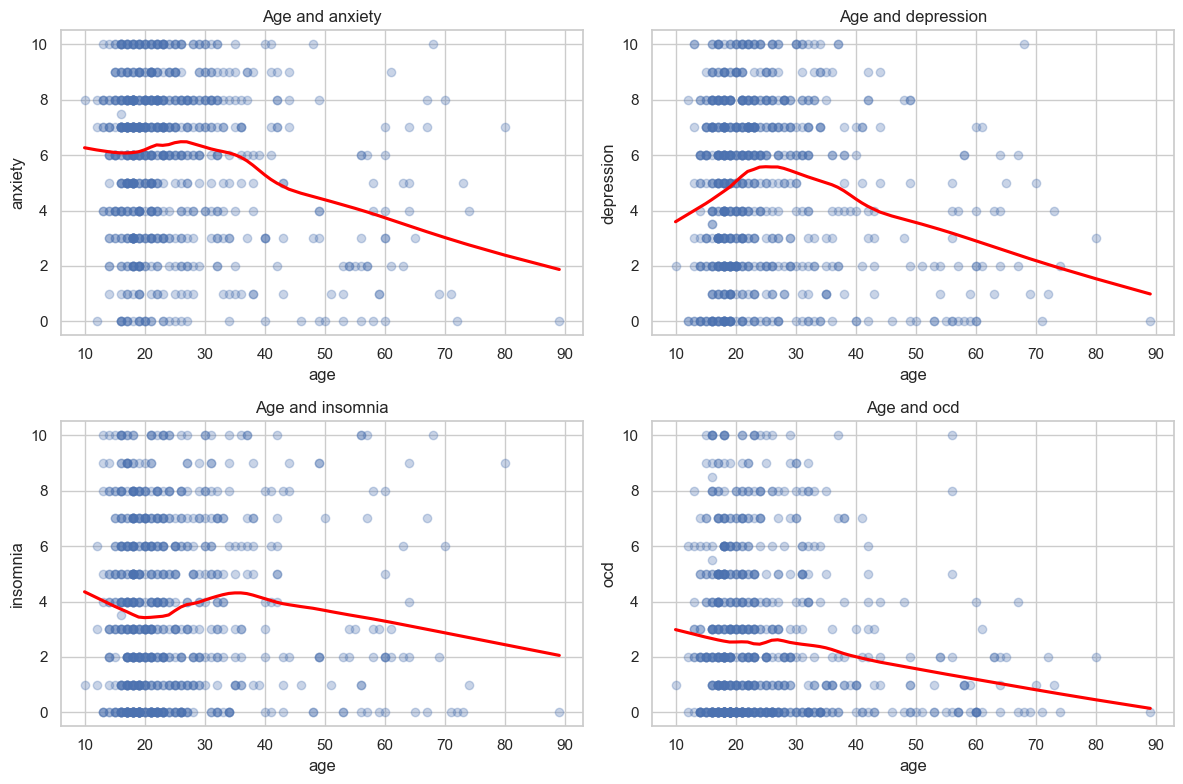

In [92]:
#RQ3. Does age matter?
#investigating whether age is associated with psychological scores and music preferences
#A-Age and psychological measures
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(mental_cols, axes.flatten()):
    sns.regplot(
        data=df,
        x="age",
        y=col,
        lowess=True,
        scatter_kws={"alpha": 0.3},
        line_kws={"color": "red"},
        ax=ax
    )
    ax.set_title(f"Age and {col}")

plt.tight_layout()
plt.show()

In [94]:
#B-Test age associations


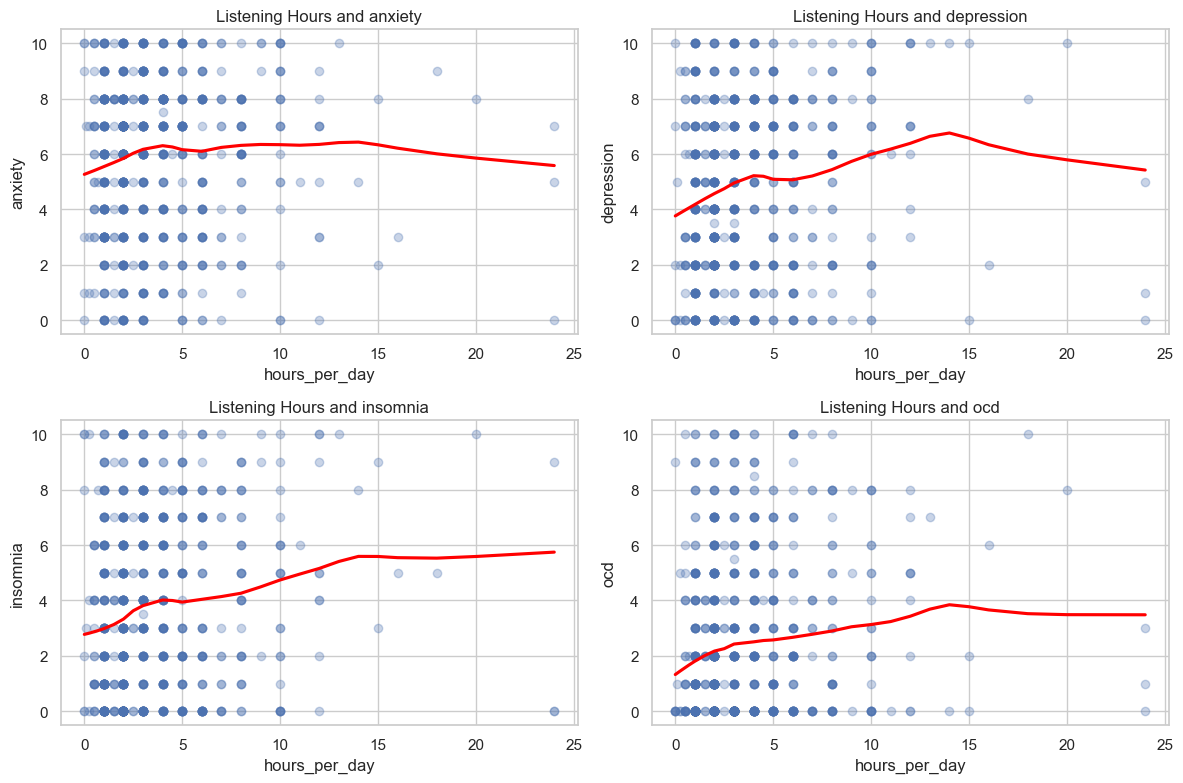

In [97]:
#RQ4. Does the number of hours spent listening to music relate to psychological well-being?
#A-Listening hours versus psychological scores
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(mental_cols, axes.flatten()):
    sns.regplot(
        data=df,
        x="hours_per_day",
        y=col,
        lowess=True,
        scatter_kws={"alpha": 0.3},
        line_kws={"color": "red"},
        ax=ax
    )
    ax.set_title(f"Listening Hours and {col}")

plt.tight_layout()
plt.show()

In [99]:
import os


repo_path = r"C:\Users\HP\Desktop\Music_effect_data_analysis_project"

# Defining the output folder and filename
output_folder = os.path.join(repo_path, "data", "processed")
os.makedirs(output_folder, exist_ok=True)

output_path = os.path.join(output_folder, "music_mental_health_cleaned_dataset.csv")

# Saving the cleaned dataset
df.to_csv(output_path, index=False)

print(f"Cleaned dataset saved to: {output_path}")

Cleaned dataset saved to: C:\Users\HP\Desktop\Music_effect_data_analysis_project\data\processed\music_mental_health_cleaned_dataset.csv
